# Applied Finance with Python
## Case Study 3: The Quarterly Client Report (reference solution)

Ms. Keller receives a report with three charts every quarter. Your predecessor built them by hand in Excel.
This notebook rebuilds all three charts in Python, so they can be reused for any client
by changing only the portfolio definition.

| Chart | Question from Ms. Keller | Finance concept |
|---|---|---|
| 1 · Performance since purchase | Which stock has performed best since I bought it? | Rebasing (index = 100) |
| 2 · Where does my return come from? | For which stock do dividends make up the largest share of my return? | Price return vs. total return |
| 3 · How deep did it fall? | Where would I have lost the most money along the way? | Drawdown |

> **Lecturer note:** this is the reference solution. The student template keeps only sections 1 and 2 (setup and data load).

## 1 · Setup

In [5]:
import pandas as pd
import yfinance as yf

### Client portfolio
Change only this cell to run the report for another client.

In [6]:
portfolio = [
    {"name": "Allianz SE",               "ticker": "ALV.DE",  "buy_date": "2021-09-30"},
    {"name": "SAP SE",                   "ticker": "SAP.DE",  "buy_date": "2022-03-15"},
    {"name": "Infineon Technologies AG", "ticker": "IFX.DE",  "buy_date": "2022-06-01"},
    {"name": "Deutsche Telekom AG",      "ticker": "DTE.DE",  "buy_date": "2023-01-03"},
    {"name": "Münchener Rück AG",        "ticker": "MUV2.DE", "buy_date": "2023-09-29"},
]

end_date = "2026-09-23"   # date of the evaluation (inclusive)

## 2 · Data load
Downloads `Close` and `Adj Close` for all stocks from Yahoo Finance (`auto_adjust=False`)
and stores them as a snapshot CSV. With `USE_SNAPSHOT = True` the notebook reads the frozen file instead,
so every student works with exactly the same numbers.

*Source: Yahoo Finance via `yfinance`, Xetra listings (`.DE`), prices in EUR.*

In [8]:
def download_prices(portfolio, end_date):
    # Download Close and Adj Close for all tickers. Returns a DataFrame with MultiIndex columns (field, ticker).
    tickers = [s["ticker"] for s in portfolio]
    start = min(s["buy_date"] for s in portfolio)
    end_exclusive = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")  # yfinance: end is exclusive
    data = yf.download(tickers, start=start, end=end_exclusive, auto_adjust=False, progress=False)
    return data[["Close", "Adj Close"]]


def load_prices(portfolio, end_date):
    data = download_prices(portfolio, end_date)
    return data


prices = load_prices(portfolio, end_date)
close = prices["Close"]
adj_close = prices["Adj Close"]

print(f"{len(prices)} trading days from {prices.index[0].date()} to {prices.index[-1].date()}")
adj_close.tail()

1270 trading days from 2021-09-30 to 2026-09-23


Ticker,ALV.DE,DTE.DE,IFX.DE,MUV2.DE,SAP.DE
Date,,,,,
2026-09-17,451.100006,28.299999,54.400002,510.600006,188.000000
2026-09-18,443.299988,27.110001,55.860001,505.799988,183.119995
2026-09-21,445.100006,27.290001,58.290001,508.799988,182.860001
2026-09-22,430.200012,27.110001,60.130001,501.799988,182.320007
2026-09-23,413.100006,26.830000,58.570000,502.600006,186.460007


## 3 · Chart 1: Performance since purchase

Each stock is rebased to **100 on its own purchase date**: `index = price / price on purchase date × 100`.
Without rebasing, a stock priced at 400 € and one priced at 25 € cannot be compared on the same axis.
We use `Adj Close`, so dividends are included.

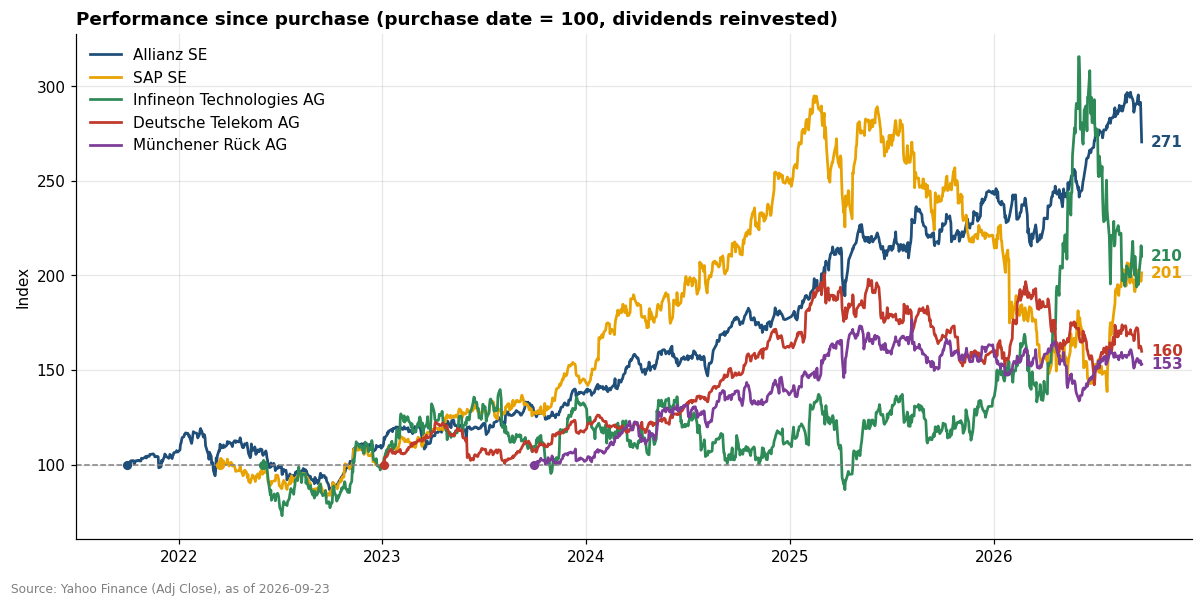